<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQk4anYFFsY3OTqb6RP4oTBhqPM0P1u80tSRA&usqp=CAU" width=75 height=50>

#<font color='Dark Maroon'><b>The details of this Notebook are explained in this YouTube video Neural Network</b></font>
<center>

  <a href="https://www.youtube.com/watch?v=fkoHrIGxIpA" target="_blank">

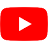

  </a>
</center>

*Algirdas Laukaitis*

##<font color='Dark Maroon'>AdventureWorks DW using TensorFlow <b>Decision Forests</b></font>


[AdventureWorks DW schema](https://github.com/aalgirdas/AdventureWorksDW/blob/main/AdventureWorksDW2008.png)

[AdventureWorks schema](https://github.com/aalgirdas/AdventureWorksDW/blob/main/AdventureWorks2008.png?raw=true)


<br><br>

---
#<font color='	Dark Maroon'>Step 1. From a csv data file that is available online to 2 DataFrame tables:  training and test</font>



## 1.1 Let’s load the vTargetMail.csv data into a dataframe from GitHub.

In [1]:
!pip install -q kagglehub
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
df_all_col = pd.read_csv(path + "/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = df_all_col.copy()     # Decision Forests dokumentas toliau naudoja `df`
print("The dataframe has {} rows and {} columns.".format(df.shape[0], df.shape[1]))

The dataframe has 7043 rows and 21 columns.


In [2]:
import os

file_path = 'july4.csv'
alternative_data = False
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    alternative_data = True



## 1.2 Next, we will examine the first row of the data to determine which information is relevant to our task.

In [3]:
#print(df.iloc[5])
df[0:5]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.3 We remove attributes that we don’t require
> *And we rename some attributes because we want to reuse the code snippets from official TensorFlow tutorials. Renaming an attribute is much easier than rewriting code.*

In [4]:
if alternative_data:
  df.drop(columns=["COD"], inplace=True)
  df.rename(columns = {'Source':'target'}, inplace = True)
else:
  df.drop(columns=["customerID"], inplace=True)

  # TotalCharges turi tuščių reikšmių, paverčiame į skaičių
  df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
  df.dropna(inplace=True)

  # SeniorCitizen yra 0/1, paverčiame tekstu (kad būtų kaip kitos kategorijos)
  df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

  # Tikslas: Yes/No -> 1/0 ir pervadinam į target
  df["Churn"] = (df["Churn"] == "Yes").astype("int64")
  df.rename(columns = {'Churn':'target'}, inplace = True)

print(df.iloc[0])


gender                        Female
SeniorCitizen                     No
Partner                          Yes
Dependents                        No
tenure                             1
PhoneService                      No
MultipleLines       No phone service
InternetService                  DSL
OnlineSecurity                    No
OnlineBackup                     Yes
DeviceProtection                  No
TechSupport                       No
StreamingTV                       No
StreamingMovies                   No
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 29.85
TotalCharges                   29.85
target                             0
Name: 0, dtype: object


## 1.4 Split the DataFrame into training and test sets

When we teach a machine learning model, we want to make sure it can perform well on new data that it has not seen before. To do this, we typically divide our data into three sets: the training set, the validation set, and the test set.

The training set is used to teach the model how to make predictions. The validation set is used to fine-tune the model to make it work better and to avoid a problem called overfitting. Overfitting happens when the model is too closely trained on the training data and doesn't perform well on new data. (But for Decision Forests we don't need validation set) The test set is used to check how well the model performs on new data after it has been trained and fine-tuned.



In [5]:
import numpy as np

train, test = np.split(df.sample(frac=1), [ int(0.9*len(df))])  # The dataset is in a single pandas DataFrame. Split it into training, and test sets using a, for example, 90:10 ratio, respectively.
print(len(train), 'training examples')
print(len(test), 'test examples')

6328 training examples
704 test examples


/usr/local/lib/python3.11/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


<br><br>

---


#<font color='	Dark Maroon'>Step 2. From DataFrame table to TensorFlow dataset data</font>

## Import TensorFlow and other libraries

In [6]:
!pip install tensorflow_decision_forests

In [7]:
import tensorflow_decision_forests as tfdf

train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(train, label='target')
test_ds = tfdf.keras.pd_dataframe_to_tf_dataset(test, label='target')


<br><br>

---


#<font color='	Dark Maroon'>Step 3. Model</font>

In [8]:
model_1 = tfdf.keras.RandomForestModel(num_trees=10 , max_depth=15 ) # num_trees=100 , max_depth=15 , verbose=0

Use /tmp/tmpt9r1a_zy as temporary training directory


<br><br>

---


#<font color='Dark Maroon'>Step 4. Train and evaluate the model</font>

<br>

##<font color='Dark Maroon'>Train 🏃‍♂️</font>

In [9]:

model_1.fit(train_ds)

Reading training dataset...
Training dataset read in 0:00:05.964541. Found 6328 examples.
Training model...
Model trained in 0:00:00.273178
Compiling model...
Model compiled.


<br>


##<font color='Dark Maroon'>Evaluate ⚖️</font>

In [10]:
model_1.compile(metrics=['accuracy'])
evaluation = model_1.evaluate(test_ds, return_dict=True)
print(f'{evaluation["accuracy"]:.4f}')



1/1 [==============================] - 1s 976ms/step - loss: 0.0000e+00 - accuracy: 0.7727
0.7727


<br>


##<font color='Dark Maroon'>Plotting the training logs 🧾</font>

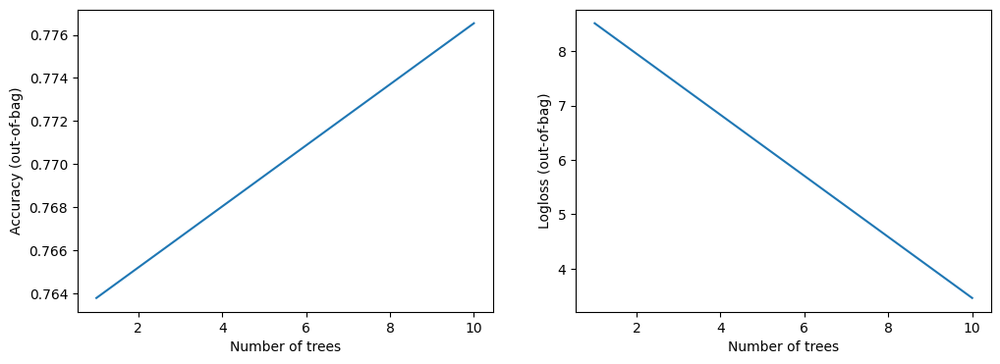

In [11]:
import matplotlib.pyplot as plt

logs = model_1.make_inspector().training_logs()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot([log.num_trees for log in logs], [log.evaluation.accuracy for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("Accuracy (out-of-bag)")

plt.subplot(1, 2, 2)
plt.plot([log.num_trees for log in logs], [log.evaluation.loss for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("Logloss (out-of-bag)")

plt.show()

<br>




##<font color='Dark Maroon'>Let's choose one tree 🌲 from the forest (tree_idx=...) and plot the model</font>

In [12]:
tfdf.model_plotter.plot_model_in_colab(model_1, tree_idx=0, max_depth=15) ## The decision tree number is defined by the tree_idx=... parameter


<br><br>

---


#<font color='Dark Maroon'> Step 5. Perform inference 🛠</font>

##<font color='Dark Maroon'> Save 💾 </font>

In [13]:
#model_1.save('AdventureWorksDW_vTargetMail_RandomForestModel_trees300.keras')
model_1.save('AdventureWorksDW_vTargetMail_RandomForestModel_trees300')

##<font color='Dark Maroon'> Load ⚙️</font>

In [14]:
import tensorflow as tf
#reloaded_model = tf.keras.models.load_model('AdventureWorksDW_vTargetMail_RandomForestModel_trees300')

reloaded_model = tf.keras.layers.TFSMLayer('AdventureWorksDW_vTargetMail_RandomForestModel_trees300', call_endpoint='serving_default')

##<font color='Dark Maroon'> New data  🗃️</font>

In [15]:
if alternative_data:
  sample = df.iloc[0].to_dict()
  del sample['target']
else:
  sample = {
      'gender': 'Male', 'SeniorCitizen': 'No', 'Partner': 'Yes', 'Dependents': 'No',
      'tenure': 5, 'PhoneService': 'Yes', 'MultipleLines': 'No',
      'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No',
      'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes',
      'StreamingMovies': 'Yes', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
      'PaymentMethod': 'Electronic check', 'MonthlyCharges': 85.0, 'TotalCharges': 420.0,
  }

In [16]:
sample

{'gender': 'Male',
 'SeniorCitizen': 'No',
 'Partner': 'Yes',
 'Dependents': 'No',
 'tenure': 5,
 'PhoneService': 'Yes',
 'MultipleLines': 'No',
 'InternetService': 'Fiber optic',
 'OnlineSecurity': 'No',
 'OnlineBackup': 'No',
 'DeviceProtection': 'No',
 'TechSupport': 'No',
 'StreamingTV': 'Yes',
 'StreamingMovies': 'Yes',
 'Contract': 'Month-to-month',
 'PaperlessBilling': 'Yes',
 'PaymentMethod': 'Electronic check',
 'MonthlyCharges': 85.0,
 'TotalCharges': 420.0}

##<font color='Dark Maroon'> Predict  🔮</font>

In [17]:
new_observation_df = pd.DataFrame([sample])
new_observation_ds = tfdf.keras.pd_dataframe_to_tf_dataset(new_observation_df)
predictions = model_1.predict(new_observation_ds)
print(predictions)

1/1 [==============================] - 0s 97ms/step
[[0.6]]


In [18]:
#predictions = reloaded_model.predict(test_ds)


<br><br><br><br>

---
---

#<font color='Dark Maroon'> Visualizing TensorFlow Decision Forest Trees with dtreeviz
</font>

In [19]:
%%capture
!pip install -q -U dtreeviz

In [20]:
import dtreeviz

from matplotlib import pyplot as plt
from IPython import display

# avoid "Arial font not found warnings"
import logging
logging.getLogger('matplotlib.font_manager').setLevel(level=logging.CRITICAL)

display.set_matplotlib_formats('retina') # generate hires plots

/tmp/ipython-input-20-2413356625.py:10: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`


## Display decision tree

In [23]:
AdventDW_features = [f.name for f in model_1.make_inspector().features()]
viz_cmodel = dtreeviz.model(model_1,
                            tree_index=0,
                            X_train=train[AdventDW_features],
                            y_train=train['target'],
                            feature_names=AdventDW_features,
                            target_name='target',
                            class_names=['No','Yes'])

In [24]:
viz_cmodel.view(scale=1.2)

In [25]:
x = train[AdventDW_features].iloc[20]
viz_cmodel.view(x=x, scale=.75)

/usr/local/lib/python3.11/dist-packages/dtreeviz/models/shadow_decision_tree.py:335: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
/usr/local/lib/python3.11/dist-packages/dtreeviz/trees.py:748: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
/usr/local/lib/python3.11/dist-packages/dtreeviz/trees.py:1671: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
/usr/local/lib/python3.11/dist-packages/dtreeviz/trees.py:1664: FutureWarning: Series.__geti